# Week 4 — HCP and Patient Segmentation: from a prescriber file to segments marketers can act on
## Case: GLUCOREN, three years after launch — 6,000 targeted prescribers, 20,000 patients, 18 months of Rx and channel data

**Applied Data Science and AI in Pharma Commercial · Columbia DSI · Fall 2026 · Monday, October 5**

Week 3 answered the Brand Lead's *how much* question (which $10M to cut). Tonight the Marketing Director asks the *who* question that comes right after it:

> *"We have 6,000 targeted prescribers and one call plan. Who are they, really — and why are we saying the same thing to all of them?"*

The structure of the night is the structure of a real segmentation engagement:

1. **The data** — an HCP master file, an HCP-month Rx/channel panel, a patient extract. Long tails everywhere.
2. **The decile baseline** — the segmentation every brand already has, and what it hides.
3. **Feature engineering from claims/Rx** — writing behavior, patient mix, switching, channel response.
4. **Unsupervised segmentation** — k-means; choosing k; profiling and naming the clusters.
5. **Alternatives** — Gaussian mixtures (soft membership), hierarchical, density-based (HDBSCAN/UMAP, optional).
6. **Evaluation** — stability, separation, and commercial interpretability. The three tests a segmentation must pass.
7. **Grade against the truth** — the data is synthetic, so we can (instructor file). A two-stage fix.
8. **Supervised segmentation** — predict next-6-month growth, then rank: Champions / Loyalists / Churners.
9. **Personas and activation** — segment cards and the segment × channel matrix; the bridge to Next Best Action (Week 5).
10. **Patient segmentation** — the same machinery on journey features; governance.

The data is **synthetic** and generated from planted behaviors, which is the only reason section 7 is possible. No real prescriber, patient, or brand is represented.

| file | grain | what it represents |
|---|---|---|
| `glucoren_hcp_master.csv` | one row per HCP (6,000) | specialty, geography, setting, tenure, patient mix (payer shares, age, comorbidity), GLUCOREN pharmacy-reject rate |
| `glucoren_hcp_monthly.csv` | one row per HCP × month (6,000 × 18) | market TRx, GLUCOREN TRx and NBRx, competitor TRx, switches in/out, rep calls, samples, emails sent/opened, web visits |
| `glucoren_patients.csv` | one row per patient (20,000) | journey features built the Week 2 way: time from diagnosis to first Rx, months on therapy, prior lines, PDC, refill gaps, switches, copay, PSP, portal, comorbidity, ER visits, discontinuation |
| `_INSTRUCTOR_hcp_segment_truth.csv`, `_INSTRUCTOR_patient_segment_truth.csv`, `_INSTRUCTOR_segmentation_truth.json` | — | the planted segments and generating parameters (in `instructor material/`; grading cells print a notice and skip if absent) |

**Feature window vs. outcome window.** Months 1–12 (Jan–Dec 2025) are the *feature window*: every segmentation feature is built from them. Months 13–18 (Jan–Jun 2026) are the *outcome window*: they are used only in section 8, to see whether a segmentation built in December would have predicted what happened next. Never let outcome-window data leak into features — this is the segmentation version of the hold-out from Week 3.


## 1. Setup

In [1]:
import json, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, silhouette_samples, calinski_harabasz_score, adjusted_rand_score, davies_bouldin_score
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40); pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
NAVY, CORAL, ICE, TEAL, GOLD, GREY, VIOLET = "#1E2761", "#FF6B6B", "#CADCFC", "#2A9D8F", "#E8B04B", "#8A8A8A", "#7B61FF"
CLUSTER_COLORS = [NAVY, CORAL, TEAL, GOLD, VIOLET, "#9AA5CE", "#6B4C2A"]
RNG = 20261005

# The package keeps data in ./data and instructor files in ./instructor material; a flat folder also works.
DATA = next((p for p in [Path("data"), Path(".")] if (p / "glucoren_hcp_master.csv").exists()), Path("."))
INSTR = next((p for p in [Path("instructor material"), Path("data"), Path(".")] if (p / "_INSTRUCTOR_hcp_segment_truth.csv").exists()), Path("instructor material"))
IMG = Path("instructor material/build/img")        # the deck builder reads figures from here; students' copies simply skip saving
def show(name=None):
    plt.tight_layout()
    if name and IMG.exists(): plt.savefig(IMG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

master = pd.read_csv(DATA / "glucoren_hcp_master.csv")
monthly = pd.read_csv(DATA / "glucoren_hcp_monthly.csv")
patients = pd.read_csv(DATA / "glucoren_patients.csv")
FEATURE_MONTHS = sorted(monthly.month.unique())[:12]; OUTCOME_MONTHS = sorted(monthly.month.unique())[12:]
print("HCPs:", master.shape, "| HCP-months:", monthly.shape, "| patients:", patients.shape)
print("feature window:", FEATURE_MONTHS[0], "→", FEATURE_MONTHS[-1], "| outcome window:", OUTCOME_MONTHS[0], "→", OUTCOME_MONTHS[-1])
master.head(3)

HCPs: (6000, 12) | HCP-months: (108000, 13) | patients: (20000, 18)
feature window: 2025-01 → 2025-12 | outcome window: 2026-01 → 2026-06


,hcp_id,specialty,region,state,practice_setting,years_in_practice,pct_medicare,pct_commercial,pct_medicaid,mean_patient_age,pct_cvd_comorbid,glucoren_reject_rate
0,H100000,PCP,Northeast,NJ,Group practice,19,0.235,0.714,0.051,53.200,0.216,0.087
1,H100001,PCP,West,WA,Health system / IDN,11,0.430,0.279,0.291,60.500,0.436,0.082
2,H100002,Endocrinology,Northeast,MA,Independent practice,22,0.248,0.556,0.196,56.200,0.278,0.008


## 2. The data — long tails everywhere
Three things to see before any model:
1. **Prescribing volume is Pareto-shaped.** A minority of HCPs write most of the market; this is why deciles exist.
2. **Share is not volume.** Two HCPs writing the same category volume can have GLUCOREN shares of 3% and 40%.
3. **Activity is not uniform.** Calls follow the current call plan — which was built on deciles. The segmentation will inherit that bias if we let it.

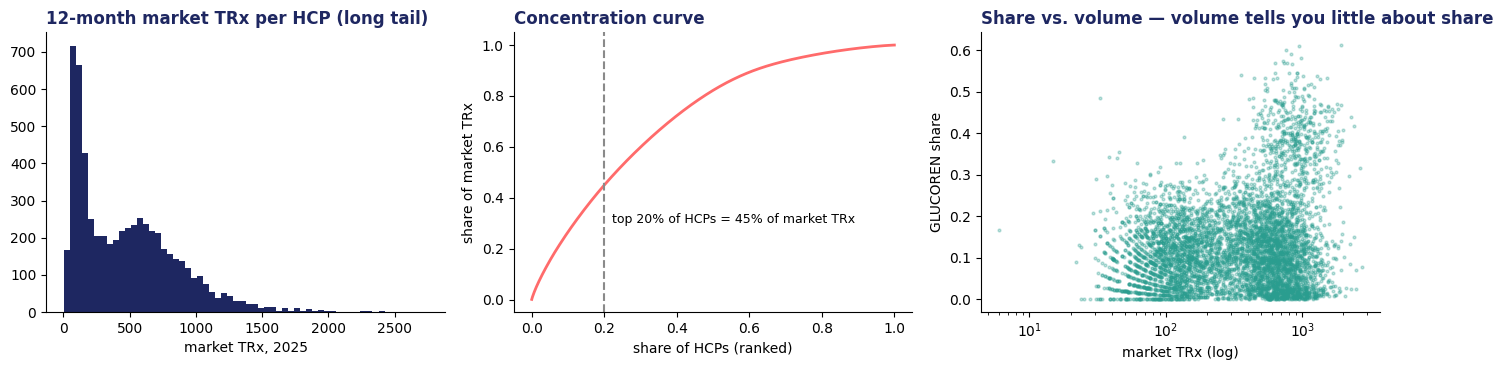

Top 20% of HCPs write 45% of category TRx; the median HCP writes 412 market TRx a year and 29 GLUCOREN TRx.
Calls per HCP-year by market-volume quintile (the call plan already targets volume):
{'Q1 low': 4.9, 'Q2': 6.1, 'Q3': 17.1, 'Q4': 20.6, 'Q5 high': 21.9}


In [2]:
feat = monthly[monthly.month.isin(FEATURE_MONTHS)]
vol = feat.groupby("hcp_id")[["market_trx", "glucoren_trx", "rep_calls"]].sum().sort_values("market_trx", ascending=False)
vol["cum_market_share"] = vol.market_trx.cumsum() / vol.market_trx.sum()
top20 = vol.cum_market_share.iloc[int(0.2 * len(vol)) - 1]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].hist(vol.market_trx, bins=60, color=NAVY); axes[0].set_title("12-month market TRx per HCP (long tail)", loc="left", color=NAVY, fontweight="bold"); axes[0].set_xlabel("market TRx, 2025")
axes[1].plot(np.linspace(0, 1, len(vol)), vol.cum_market_share, color=CORAL, lw=2); axes[1].axvline(0.2, color=GREY, ls="--"); axes[1].text(0.22, 0.3, f"top 20% of HCPs = {top20:.0%} of market TRx", fontsize=9)
axes[1].set_title("Concentration curve", loc="left", color=NAVY, fontweight="bold"); axes[1].set_xlabel("share of HCPs (ranked)"); axes[1].set_ylabel("share of market TRx")
share = (vol.glucoren_trx / vol.market_trx.clip(lower=1))
axes[2].scatter(vol.market_trx, share, s=4, alpha=0.3, color=TEAL); axes[2].set_xscale("log"); axes[2].set_xlabel("market TRx (log)"); axes[2].set_ylabel("GLUCOREN share")
axes[2].set_title("Share vs. volume — volume tells you little about share", loc="left", color=NAVY, fontweight="bold")
show("volume")
print(f"Top 20% of HCPs write {top20:.0%} of category TRx; the median HCP writes {vol.market_trx.median():.0f} market TRx a year and {vol.glucoren_trx.median():.0f} GLUCOREN TRx.")
print("Calls per HCP-year by market-volume quintile (the call plan already targets volume):")
vol["vol_quintile"] = pd.qcut(vol.market_trx.rank(method="first"), 5, labels=["Q1 low", "Q2", "Q3", "Q4", "Q5 high"])
print(vol.groupby("vol_quintile", observed=True).rep_calls.mean().round(1).to_dict())

## 3. The decile baseline — and what it hides
Every brand has a **decile segmentation**: rank HCPs by category (or brand) volume, cut into ten equal-count groups, and call the top deciles more. It is cheap, defensible, and blind to behavior. Deciles answer *"how big?"*; a marketer needs *"how big, how loyal, moving which way, reachable how?"*

        hcps  market_trx  brand_trx  share_p10  share_median  share_p90  market_share_of_total
decile                                                                                        
1        600       35622       3563      0.014         0.090      0.200                  0.012
2        600       59486       6219      0.012         0.100      0.198                  0.021
3        600       84025       9283      0.017         0.103      0.208                  0.029
4        600      127252      15060      0.023         0.109      0.215                  0.044
5        600      204691      27036      0.025         0.122      0.242                  0.071
6        600      285429      38780      0.026         0.119      0.257                  0.099
7        600      355324      48697      0.014         0.116      0.298                  0.124
8        600      427763      61728      0.014         0.110      0.358                  0.149
9        600      528932      85685      0.016    

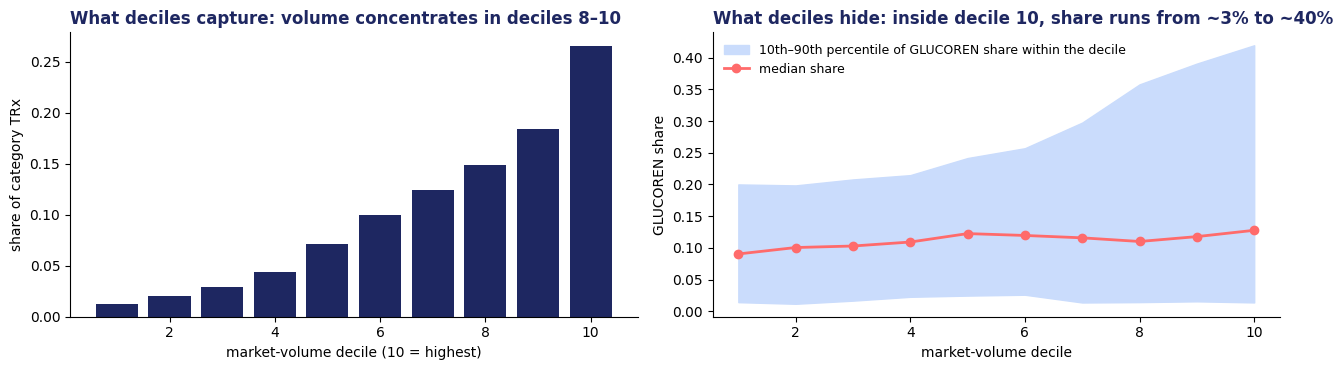

Decile 10: 600 HCPs. GLUCOREN share 10th pct = 1%, 90th pct = 42%. Same call frequency for all of them.


In [3]:
vol["decile"] = pd.qcut(vol.market_trx.rank(method="first"), 10, labels=range(1, 11)).astype(int)
vol["share"] = share
dec = vol.groupby("decile").agg(hcps=("market_trx", "size"), market_trx=("market_trx", "sum"), brand_trx=("glucoren_trx", "sum"),
                                share_p10=("share", lambda s: s.quantile(0.10)), share_median=("share", "median"), share_p90=("share", lambda s: s.quantile(0.90)))
dec["market_share_of_total"] = dec.market_trx / dec.market_trx.sum()
print(dec.round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].bar(dec.index, dec.market_share_of_total, color=NAVY); axes[0].set_xlabel("market-volume decile (10 = highest)"); axes[0].set_ylabel("share of category TRx")
axes[0].set_title("What deciles capture: volume concentrates in deciles 8–10", loc="left", color=NAVY, fontweight="bold")
axes[1].fill_between(dec.index, dec.share_p10, dec.share_p90, color=ICE, label="10th–90th percentile of GLUCOREN share within the decile")
axes[1].plot(dec.index, dec.share_median, color=CORAL, lw=2, marker="o", label="median share"); axes[1].legend(frameon=False, fontsize=9)
axes[1].set_xlabel("market-volume decile"); axes[1].set_ylabel("GLUCOREN share"); axes[1].set_title("What deciles hide: inside decile 10, share runs from ~3% to ~40%", loc="left", color=NAVY, fontweight="bold")
show("decile")
d10 = vol[vol.decile == 10]
print(f"Decile 10: {len(d10)} HCPs. GLUCOREN share 10th pct = {d10.share.quantile(.1):.0%}, 90th pct = {d10.share.quantile(.9):.0%}. Same call frequency for all of them.")

## 4. Feature engineering from claims/Rx — the four families
A behavioral segmentation is only as good as its features, and in pharma the features come from the data you met in Week 2 (Rx panel, claims) plus the activity data the brand generates itself. We build **one row per HCP** from the 12 feature months, in four families the syllabus names:

| family | features tonight | source in a real brand |
|---|---|---|
| **Writing behavior** | market volume; GLUCOREN share; share trend (H2 − H1); NBRx share of brand TRx | Rx panel (Xponent-style projections, Week 2) |
| **Patient mix** | % Medicare, mean patient age, % with CV comorbidity; GLUCOREN pharmacy-reject rate | claims (payer of record, diagnosis codes), formulary/reject data (Week 2, category 4) |
| **Switching** | switch-in rate (share of NBRx that came from a competitor); switch-out rate | longitudinal Rx (patient-level, Week 2 LOT logic) |
| **Channel response** | calls received; email open rate; web visits; call response (correlation of this month's brand TRx with last month's calls) | CRM / marketing automation / web analytics |

Two practical rules: **log-transform counts** (volume, calls, visits are Pareto-shaped) and **rates over counts** wherever a count would just re-encode volume.

In [4]:
f = feat.copy(); f["mi"] = f.groupby("hcp_id").cumcount()
g = f.groupby("hcp_id")
F = pd.DataFrame({"market_trx": g.market_trx.sum(), "brand_trx": g.glucoren_trx.sum(), "nbrx": g.glucoren_nbrx.sum(),
                  "switch_in": g.switch_in.sum(), "switch_out": g.switch_out.sum(), "rep_calls": g.rep_calls.sum(),
                  "emails_sent": g.emails_sent.sum(), "emails_opened": g.emails_opened.sum(), "web_visits": g.web_visits.sum()})
F["brand_share"] = F.brand_trx / F.market_trx.clip(lower=1)
F["nbrx_share"] = F.nbrx / F.brand_trx.clip(lower=1)
half = f.assign(h2=f.mi >= 6).groupby(["hcp_id", "h2"])[["market_trx", "glucoren_trx"]].sum()
sh = (half.glucoren_trx / half.market_trx.clip(lower=1)).unstack()
F["share_trend"] = sh[True] - sh[False]                                  # H2 share minus H1 share
F["switch_in_rate"] = F.switch_in / F.nbrx.clip(lower=1)
F["switch_out_rate"] = F.switch_out / F.brand_trx.clip(lower=1)
F["email_open_rate"] = F.emails_opened / F.emails_sent.clip(lower=1)
f["lag_calls"] = g.rep_calls.shift(1)
def call_response(d):
    d = d.dropna(subset=["lag_calls"])
    if d.lag_calls.std() == 0 or d.glucoren_trx.std() == 0: return 0.0
    return float(np.corrcoef(d.lag_calls, d.glucoren_trx)[0, 1])
F["call_response"] = f.groupby("hcp_id").apply(call_response)      # correlation of brand TRx with last month's calls
F = F.join(master.set_index("hcp_id")[["specialty", "region", "practice_setting", "pct_medicare", "mean_patient_age", "pct_cvd_comorbid", "glucoren_reject_rate"]])
FEATURES = ["market_trx", "brand_share", "share_trend", "nbrx_share",                       # writing behavior
            "pct_medicare", "mean_patient_age", "pct_cvd_comorbid", "glucoren_reject_rate",   # patient mix / access
            "switch_in_rate", "switch_out_rate",                                              # switching
            "rep_calls", "email_open_rate", "web_visits", "call_response"]                    # channel response
print(F[FEATURES].describe().T[["mean", "std", "min", "50%", "max"]])

                        mean     std    min     50%       max
market_trx           478.449 383.439  6.000 412.000 2,744.000
brand_share            0.132   0.109  0.000   0.110     0.612
share_trend            0.016   0.057 -0.357   0.011     0.333
nbrx_share             0.333   0.177  0.000   0.335     1.000
pct_medicare           0.383   0.134  0.020   0.372     0.843
mean_patient_age      59.455   5.346 41.500  59.300    81.100
pct_cvd_comorbid       0.315   0.076  0.062   0.315     0.636
glucoren_reject_rate   0.109   0.093  0.000   0.086     0.487
switch_in_rate         0.210   0.224  0.000   0.160     1.000
switch_out_rate        0.012   0.029  0.000   0.000     0.500
rep_calls             14.113   8.881  0.000  15.000    42.000
email_open_rate        0.247   0.125  0.000   0.231     0.688
web_visits            18.018  16.910  0.000   9.000    74.000
call_response          0.036   0.318 -0.795   0.014     0.904


### 4b. Feature hygiene — the step that separates a segmentation from a scatter of outliers
Before scaling, look at every *rate*. A rate with a tiny denominator (switch-out rate for an HCP who wrote 4 GLUCOREN scripts; NBRx share for one who wrote 2) is noise dressed as a behavior, and k-means — which minimizes squared distance — will happily build a cluster out of the noisiest 1% of HCPs. Watch it happen, then fix it: winsorize rates at the 1st/99th percentiles, and drop a feature whose information is *only* its denominator.

In [5]:
X0 = F[FEATURES].copy()
for c in ["market_trx", "rep_calls", "web_visits"]: X0[c] = np.log1p(X0[c])
km0 = KMeans(n_clusters=5, n_init=20, random_state=RNG).fit(StandardScaler().fit_transform(X0))
sizes0 = pd.Series(km0.labels_).value_counts().sort_index(); tiny = sizes0.idxmin()
print("k-means (k=5) on the raw feature set — cluster sizes:", sizes0.to_dict(), f"| inertia {km0.inertia_:,.0f}")
print(f"\nThe smallest cluster ({sizes0[tiny]} HCPs):")
print(F.loc[km0.labels_ == tiny, ["brand_trx", "switch_out", "switch_out_rate", "nbrx_share", "call_response"]].describe().T[["mean", "min", "50%", "max"]].round(3))
print(f"\nUniverse: switch_out_rate 99th percentile = {F.switch_out_rate.quantile(.99):.2f}; this cluster's median = {F.loc[km0.labels_ == tiny, 'switch_out_rate'].median():.2f} on a median of {F.loc[km0.labels_ == tiny, 'brand_trx'].median():.0f} brand TRx.")
print("\nswitch_out_rate by brand-TRx band — same mean everywhere, but the spread explodes where the denominator is small:")
print(F.groupby(pd.cut(F.brand_trx, [-1, 10, 20, 50, 100, 10_000], labels=["0–10", "11–20", "21–50", "51–100", "100+"]), observed=True).switch_out_rate.agg(["mean", "std", "max"]).round(3))
print("\nRule: a rate needs a denominator. Below ~20 brand TRx, switch-out rate is a coin flip — and the k-means objective *prefers* the solution that isolates those coin flips (lower inertia). Drop it (switch-in rate carries the switching signal) and winsorize the other rates.")

k-means (k=5) on the raw feature set — cluster sizes: {0: 72, 1: 806, 2: 1453, 3: 1303, 4: 2366} | inertia 44,708

The smallest cluster (72 HCPs):
                  mean    min    50%    max
brand_trx        7.194  2.000  7.000 25.000
switch_out       1.181  1.000  1.000  3.000
switch_out_rate  0.194  0.100  0.167  0.500
nbrx_share       0.316  0.000  0.333  1.000
call_response   -0.007 -0.585 -0.010  0.817

Universe: switch_out_rate 99th percentile = 0.12; this cluster's median = 0.17 on a median of 7 brand TRx.

switch_out_rate by brand-TRx band — same mean everywhere, but the spread explodes where the denominator is small:
           mean   std   max
brand_trx                  
0–10      0.010 0.047 0.500
11–20     0.013 0.028 0.188
21–50     0.012 0.020 0.120
51–100    0.013 0.016 0.098
100+      0.011 0.012 0.063

Rule: a rate needs a denominator. Below ~20 brand TRx, switch-out rate is a coin flip — and the k-means objective *prefers* the solution that isolates those coin flips (

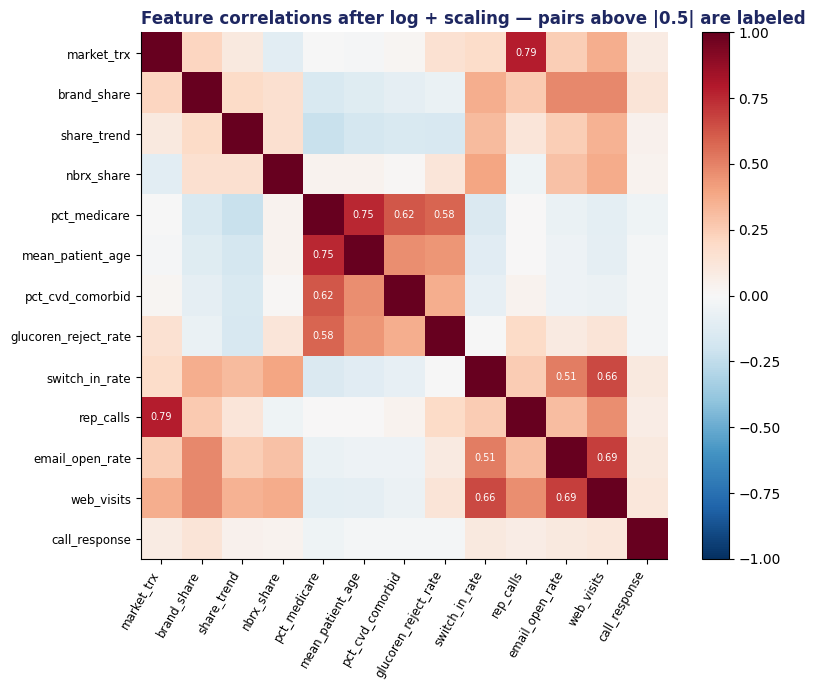

Highly correlated pairs mean one behavior is being counted twice; k-means will weight it twice. Tonight we keep them and note it; a PCA or a feature-family weighting is the usual fix.


In [6]:
FEATURES = [c for c in FEATURES if c != "switch_out_rate"]
X = F[FEATURES].copy()
for c in ["market_trx", "rep_calls", "web_visits"]: X[c] = np.log1p(X[c])
for c in ["share_trend", "nbrx_share", "switch_in_rate", "call_response", "email_open_rate"]:
    lo, hi = X[c].quantile([0.01, 0.99]); X[c] = X[c].clip(lo, hi)
scaler = StandardScaler().fit(X); Xs = scaler.transform(X)
corr = X.corr()
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1); ax.set_xticks(range(len(FEATURES))); ax.set_xticklabels(FEATURES, rotation=60, ha="right", fontsize=8.5)
ax.set_yticks(range(len(FEATURES))); ax.set_yticklabels(FEATURES, fontsize=8.5); plt.colorbar(im, fraction=0.04)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        if abs(corr.iloc[i, j]) >= 0.5 and i != j: ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white")
ax.set_title("Feature correlations after log + scaling — pairs above |0.5| are labeled", loc="left", color=NAVY, fontweight="bold")
show("features_corr")
print("Highly correlated pairs mean one behavior is being counted twice; k-means will weight it twice. Tonight we keep them and note it; a PCA or a feature-family weighting is the usual fix.")

## 5. Unsupervised segmentation — k-means
k-means finds k centroids that minimize within-cluster squared distance. It is fast, deterministic given a seed, and it assumes round clusters of similar size in scaled space — which behavioral data rarely gives you. That is fine: it is the industry's workhorse *because it is easy to explain*, and the evaluation in section 6 tells you when it is lying.

**Choosing k.** Inertia always falls with k (the elbow is a judgement call). Silhouette (−1…1: how much closer each point is to its own cluster than to the nearest other) and Calinski–Harabasz (between/within variance ratio) give two more views. Then the commercial test: *can marketing run k different plays?* Four to six is where most HCP segmentations land.

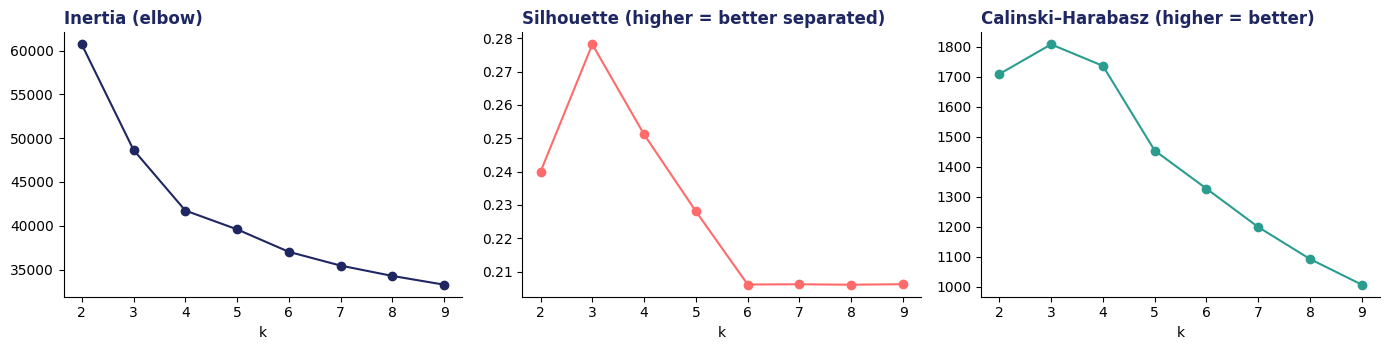

 k    inertia  silhouette  calinski_harabasz
 2 60,704.000       0.240          1,709.000
 3 48,659.000       0.278          1,808.000
 4 41,739.000       0.251          1,736.000
 5 39,591.000       0.228          1,454.000
 6 37,024.000       0.206          1,327.000
 7 35,453.000       0.206          1,199.000
 8 34,274.000       0.206          1,092.000
 9 33,275.000       0.206          1,007.000


In [7]:
ks = range(2, 10); inertia, sil, ch = [], [], []
rs = np.random.default_rng(RNG).choice(len(Xs), 3000, replace=False)     # silhouette on a sample for speed
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RNG).fit(Xs)
    inertia.append(km.inertia_); sil.append(silhouette_score(Xs[rs], km.labels_[rs])); ch.append(calinski_harabasz_score(Xs, km.labels_))
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].plot(ks, inertia, marker="o", color=NAVY); axes[0].set_title("Inertia (elbow)", loc="left", color=NAVY, fontweight="bold"); axes[0].set_xlabel("k")
axes[1].plot(ks, sil, marker="o", color=CORAL); axes[1].set_title("Silhouette (higher = better separated)", loc="left", color=NAVY, fontweight="bold"); axes[1].set_xlabel("k")
axes[2].plot(ks, ch, marker="o", color=TEAL); axes[2].set_title("Calinski–Harabasz (higher = better)", loc="left", color=NAVY, fontweight="bold"); axes[2].set_xlabel("k")
show("choose_k")
print(pd.DataFrame({"k": list(ks), "inertia": np.round(inertia, 0), "silhouette": np.round(sil, 3), "calinski_harabasz": np.round(ch, 0)}).to_string(index=False))

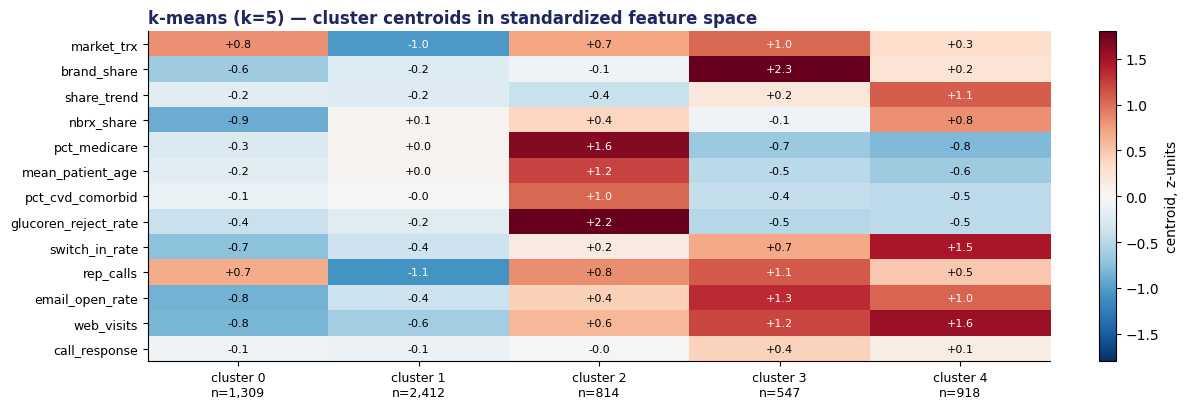

         hcps  market_trx  brand_trx  share_of_brand_trx  brand_share
cluster                                                              
0        1309     1020105      65520               0.150        0.064
1        2412      331008      35484               0.081        0.107
2         814      563432      69230               0.159        0.123
3         547      515132     196160               0.449        0.381
4         918      441019      70110               0.161        0.159

Profile in original units (means):
         market_trx  brand_share  share_trend  nbrx_share  switch_in_rate  rep_calls  email_open_rate  web_visits  call_response  pct_medicare  glucoren_reject_rate
cluster                                                                                                                                                             
0           779.301        0.063        0.006       0.174           0.045     19.277            0.142       6.063          0.014         0.347  

In [8]:
K = 5
km = KMeans(n_clusters=K, n_init=20, random_state=RNG).fit(Xs)
F["cluster"] = km.labels_
prof = F.groupby("cluster")[FEATURES].mean()
z = (prof - X.mean()) / X.std()                                   # profile in z-units of the (unlogged) feature means — for reading
z_log = pd.DataFrame(km.cluster_centers_, columns=FEATURES)       # centroids in scaled space — what k-means actually used
sizes = F.cluster.value_counts().sort_index()
value = F.groupby("cluster").agg(hcps=("brand_trx", "size"), market_trx=("market_trx", "sum"), brand_trx=("brand_trx", "sum"))
value["share_of_brand_trx"] = value.brand_trx / value.brand_trx.sum(); value["brand_share"] = value.brand_trx / value.market_trx
fig, ax = plt.subplots(figsize=(12, 4.2))
im = ax.imshow(z_log.T, cmap="RdBu_r", vmin=-1.8, vmax=1.8, aspect="auto")
ax.set_yticks(range(len(FEATURES))); ax.set_yticklabels(FEATURES, fontsize=9); ax.set_xticks(range(K)); ax.set_xticklabels([f"cluster {c}\nn={sizes[c]:,}" for c in range(K)], fontsize=9)
for i in range(len(FEATURES)):
    for j in range(K): ax.text(j, i, f"{z_log.iloc[j, i]:+.1f}", ha="center", va="center", fontsize=8, color="white" if abs(z_log.iloc[j, i]) > 0.9 else "black")
plt.colorbar(im, fraction=0.03, label="centroid, z-units"); ax.set_title(f"k-means (k={K}) — cluster centroids in standardized feature space", loc="left", color=NAVY, fontweight="bold")
show("profile_heat")
print(value.round(3))
print("\nProfile in original units (means):"); print(prof[["market_trx", "brand_share", "share_trend", "nbrx_share", "switch_in_rate", "rep_calls", "email_open_rate", "web_visits", "call_response", "pct_medicare", "glucoren_reject_rate"]].round(3))

**Reading a profile.** Go feature family by family and write one sentence per cluster before you name anything. A name is a hypothesis about a *behavior*, and it has to be defensible from the heatmap alone. Then check the value table: a segment that is 40% of HCPs and 8% of brand TRx is a real segment — it just needs a cheap play.

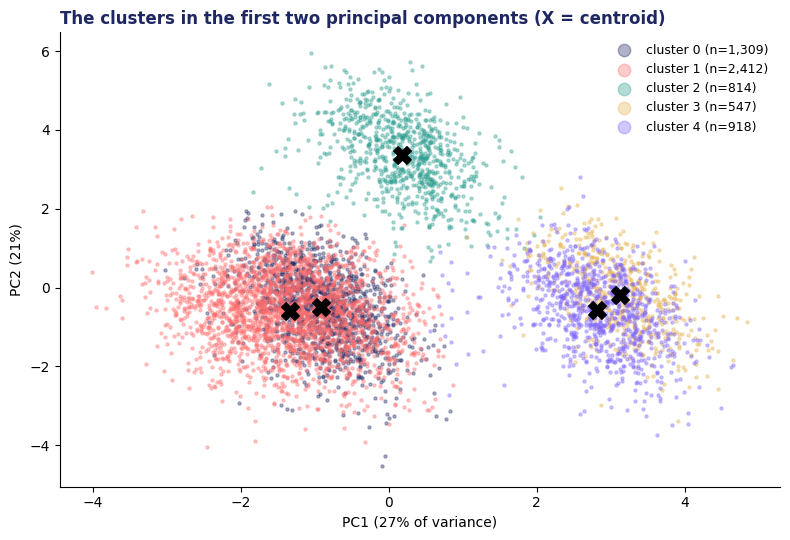

Loadings — what each axis means:
                        PC1    PC2
pct_medicare         -0.190  0.520
mean_patient_age     -0.160  0.460
pct_cvd_comorbid     -0.140  0.420
glucoren_reject_rate -0.030  0.460
call_response         0.100  0.010
nbrx_share            0.190  0.100
share_trend           0.260 -0.100
market_trx            0.270  0.180
rep_calls             0.300  0.210
brand_share           0.340  0.020
switch_in_rate        0.390  0.050
email_open_rate       0.400  0.120
web_visits            0.460  0.140


In [9]:
pca = PCA(n_components=2, random_state=RNG).fit(Xs); P2 = pca.transform(Xs)
fig, ax = plt.subplots(figsize=(8, 5.5))
for c in range(K):
    m = F.cluster.values == c
    ax.scatter(P2[m, 0], P2[m, 1], s=5, alpha=0.35, color=CLUSTER_COLORS[c], label=f"cluster {c} (n={m.sum():,})")
cent = pca.transform(km.cluster_centers_); ax.scatter(cent[:, 0], cent[:, 1], s=160, marker="X", color="black", zorder=5)
ax.legend(frameon=False, markerscale=4, fontsize=9); ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)"); ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.set_title("The clusters in the first two principal components (X = centroid)", loc="left", color=NAVY, fontweight="bold")
show("pca")
load = pd.DataFrame(pca.components_.T, index=FEATURES, columns=["PC1", "PC2"]).round(2)
print("Loadings — what each axis means:"); print(load.sort_values("PC1"))

## 6. Alternatives to k-means — and when each earns its place
| method | what changes | when it matters in pharma |
|---|---|---|
| **Gaussian mixture (GMM)** | Soft membership (a probability per segment); ellipsoidal clusters; BIC to choose k | HCPs on a segment boundary get a probability, not a label — useful for the NBA layer next week |
| **Hierarchical (agglomerative)** | A dendrogram; no k up front; nested segments | Brand teams love nested segmentations ("high-value → loyal / contested") |
| **HDBSCAN** (density-based) | Finds dense regions; leaves noise unassigned; no k | Real HCP data has a large "no clear behavior" mass — HDBSCAN says so instead of forcing it |
| **UMAP** (projection) | Non-linear 2-D map for looking, not for clustering per se | Presentations; sanity-checking whether clusters are real islands |

Tonight we fit the first two on the same features and compare labels with the adjusted Rand index (ARI: 0 = chance agreement, 1 = identical partition). HDBSCAN/UMAP run only if installed (`pip install umap-learn`; HDBSCAN ships with scikit-learn ≥ 1.3).

In [10]:
bic = {k: GaussianMixture(n_components=k, covariance_type="full", random_state=RNG, n_init=2).fit(Xs).bic(Xs) for k in range(2, 9)}
gmm = GaussianMixture(n_components=K, covariance_type="full", random_state=RNG, n_init=3).fit(Xs)
F["gmm"] = gmm.predict(Xs); resp = gmm.predict_proba(Xs); F["gmm_confidence"] = resp.max(axis=1)
agg = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(Xs[rs]); F["ward"] = np.nan; F.iloc[rs, F.columns.get_loc("ward")] = agg.labels_
print("GMM BIC by k (lower is better):", {k: round(v) for k, v in bic.items()})
print(f"ARI k-means vs GMM: {adjusted_rand_score(F.cluster, F.gmm):.3f} | k-means vs Ward (3,000-HCP sample): {adjusted_rand_score(F.cluster.iloc[rs], F.ward.iloc[rs]):.3f}")
print(f"GMM: {(F.gmm_confidence < 0.7).mean():.1%} of HCPs have < 70% membership probability — the boundary population an NBA engine should treat differently.")
print(pd.crosstab(F.cluster, F.gmm, rownames=["k-means"], colnames=["GMM"]))

GMM BIC by k (lower is better): {2: 176833, 3: 169297, 4: 163715, 5: 139792, 6: 138575, 7: 139151, 8: 138453}
ARI k-means vs GMM: 0.476 | k-means vs Ward (3,000-HCP sample): 0.962
GMM: 0.2% of HCPs have < 70% membership probability — the boundary population an NBA engine should treat differently.
GMM        0    1    2     3     4
k-means                           
0        401    0    0    22   886
1          0    0    0  1082  1330
2          0    0  798     8     8
3          0  546    1     0     0
4          0  898    2    18     0


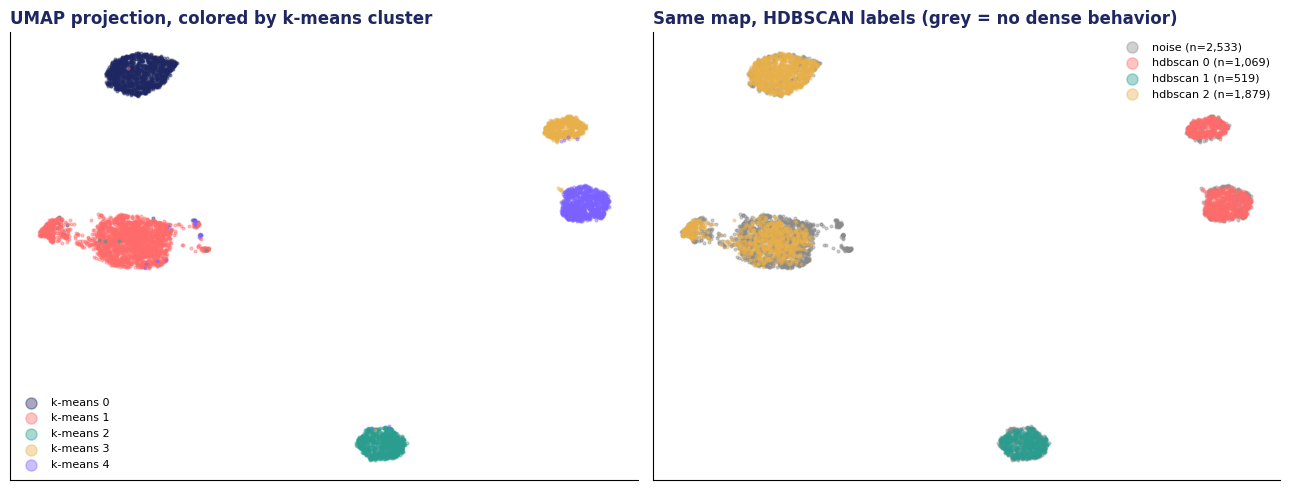

HDBSCAN found 3 dense clusters and left 42% of HCPs unassigned; ARI vs k-means (assigned HCPs only): 0.578


In [11]:
HAVE_UMAP = False
try:
    import umap; from sklearn.cluster import HDBSCAN
    HAVE_UMAP = True
except Exception as e:
    print("umap-learn / HDBSCAN not available — skipping the optional density-based view.", e)
if HAVE_UMAP:
    emb = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=RNG).fit_transform(Xs)
    hdb = HDBSCAN(min_cluster_size=150, min_samples=20).fit(Xs); F["hdbscan"] = hdb.labels_
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for c in range(K):
        m = F.cluster.values == c; axes[0].scatter(emb[m, 0], emb[m, 1], s=4, alpha=0.4, color=CLUSTER_COLORS[c], label=f"k-means {c}")
    axes[0].legend(frameon=False, markerscale=4, fontsize=8); axes[0].set_title("UMAP projection, colored by k-means cluster", loc="left", color=NAVY, fontweight="bold")
    labs = sorted(F.hdbscan.unique())
    for i, c in enumerate(labs):
        m = F.hdbscan.values == c; axes[1].scatter(emb[m, 0], emb[m, 1], s=4, alpha=0.4, color=GREY if c == -1 else CLUSTER_COLORS[i % len(CLUSTER_COLORS)], label=("noise" if c == -1 else f"hdbscan {c}") + f" (n={m.sum():,})")
    axes[1].legend(frameon=False, markerscale=4, fontsize=8); axes[1].set_title("Same map, HDBSCAN labels (grey = no dense behavior)", loc="left", color=NAVY, fontweight="bold")
    for ax in axes: ax.set_xticks([]); ax.set_yticks([])
    show("umap")
    print(f"HDBSCAN found {len([c for c in labs if c != -1])} dense clusters and left {(F.hdbscan == -1).mean():.0%} of HCPs unassigned; ARI vs k-means (assigned HCPs only): {adjusted_rand_score(F.cluster[F.hdbscan != -1], F.hdbscan[F.hdbscan != -1]):.3f}")

## 7. Evaluation — the three tests
A segmentation is a *decision artifact*, not a model score. It must pass three tests before a brand team builds a year's plan on it:

1. **Stability.** Re-run on a bootstrap resample, on a different seed, on 11 months instead of 12 — do the same HCPs land together? (ARI between runs; per-HCP agreement.) An unstable segmentation reshuffles the field's target lists every refresh — the single fastest way to lose the sales force.
2. **Separation.** Silhouette per cluster, Davies–Bouldin. Weak separation is normal in behavioral data; *very* weak separation for one cluster means it is a leftover, not a behavior.
3. **Commercial interpretability.** Each segment: a one-line behavior, a size, a value (brand TRx now and headroom), a reachability (do we have a channel that works for them?), and a *different play*. If two segments get the same play, merge them.

Bootstrap ARI vs reference: mean 0.971 (min 0.685) | matched per-HCP agreement: 97.4%
Seed ARI (5 seeds): [0.999 1.    1.    0.685 0.999] | 11-month feature window vs 12-month: ARI 0.997

Overall silhouette 0.227 | Davies–Bouldin 1.573 (lower is better)
         mean_silhouette  share_negative
cluster                                 
0                  0.327           0.000
1                  0.117           0.084
2                  0.397           0.000
3                  0.268           0.000
4                  0.204           0.015


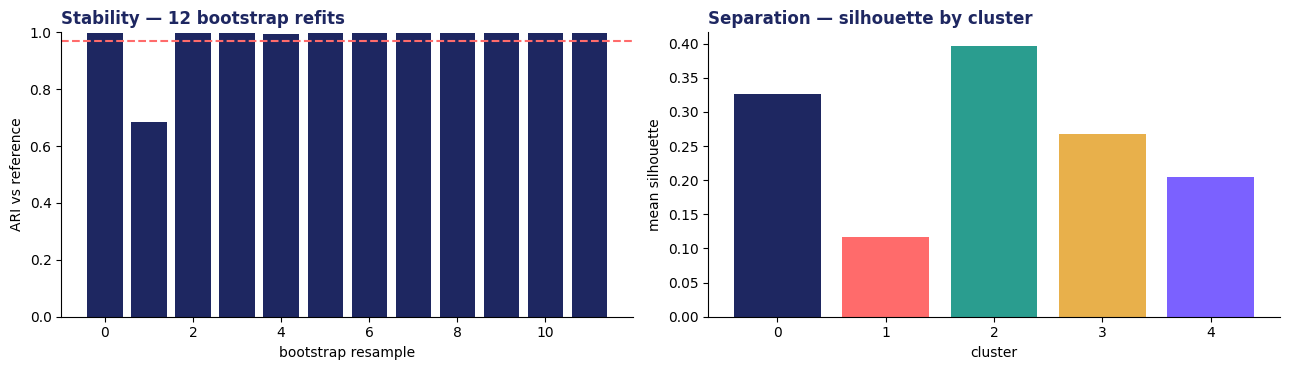

In [12]:
# 1. Stability — bootstrap resamples and seeds; labels are matched to the reference run through the confusion matrix
from scipy.optimize import linear_sum_assignment
def matched_agreement(ref, new):
    ct = pd.crosstab(ref, new).values; r, c = linear_sum_assignment(-ct); return ct[r, c].sum() / ct.sum()
boot_ari, boot_agree = [], []
rng_b = np.random.default_rng(RNG)
for b in range(12):
    idx = rng_b.choice(len(Xs), len(Xs), replace=True)
    kb = KMeans(n_clusters=K, n_init=5, random_state=b).fit(Xs[idx]); lab = kb.predict(Xs)
    boot_ari.append(adjusted_rand_score(F.cluster, lab)); boot_agree.append(matched_agreement(F.cluster, lab))
seed_ari = [adjusted_rand_score(F.cluster, KMeans(n_clusters=K, n_init=5, random_state=s).fit_predict(Xs)) for s in range(5)]
# a different feature window: drop the last feature month and rebuild the four writing-behavior features
f11 = feat[feat.month.isin(FEATURE_MONTHS[:11])]; g11 = f11.groupby("hcp_id")
X11 = X.copy(); X11["market_trx"] = np.log1p(g11.market_trx.sum()); X11["brand_share"] = g11.glucoren_trx.sum() / g11.market_trx.sum().clip(lower=1)
lab11 = KMeans(n_clusters=K, n_init=5, random_state=RNG).fit_predict(scaler.transform(X11))
print(f"Bootstrap ARI vs reference: mean {np.mean(boot_ari):.3f} (min {np.min(boot_ari):.3f}) | matched per-HCP agreement: {np.mean(boot_agree):.1%}")
print(f"Seed ARI (5 seeds): {np.round(seed_ari, 3)} | 11-month feature window vs 12-month: ARI {adjusted_rand_score(F.cluster, lab11):.3f}")
# 2. Separation
ss = silhouette_samples(Xs[rs], F.cluster.values[rs])
sep = pd.DataFrame({"cluster": F.cluster.values[rs], "silhouette": ss}).groupby("cluster").silhouette.agg(["mean", lambda s: (s < 0).mean()]); sep.columns = ["mean_silhouette", "share_negative"]
print(f"\nOverall silhouette {silhouette_score(Xs[rs], F.cluster.values[rs]):.3f} | Davies–Bouldin {davies_bouldin_score(Xs, F.cluster):.3f} (lower is better)")
print(sep.round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].bar(range(len(boot_ari)), boot_ari, color=NAVY); axes[0].axhline(np.mean(boot_ari), color=CORAL, ls="--"); axes[0].set_ylim(0, 1); axes[0].set_xlabel("bootstrap resample"); axes[0].set_ylabel("ARI vs reference")
axes[0].set_title("Stability — 12 bootstrap refits", loc="left", color=NAVY, fontweight="bold")
axes[1].bar(sep.index, sep.mean_silhouette, color=[CLUSTER_COLORS[c] for c in sep.index]); axes[1].set_xlabel("cluster"); axes[1].set_ylabel("mean silhouette")
axes[1].set_title("Separation — silhouette by cluster", loc="left", color=NAVY, fontweight="bold")
show("stability")

In [13]:
# 3. Commercial interpretability — the segment card table (sizes, value, headroom, reachability)
card = F.groupby("cluster").agg(hcps=("brand_trx", "size"), brand_trx=("brand_trx", "sum"), market_trx=("market_trx", "sum"),
                                 share=("brand_share", "mean"), trend=("share_trend", "mean"), nbrx_share=("nbrx_share", "mean"),
                                 calls_per_hcp=("rep_calls", "mean"), call_resp=("call_response", "mean"), email_open=("email_open_rate", "mean"),
                                 web=("web_visits", "mean"), medicare=("pct_medicare", "mean"), reject=("glucoren_reject_rate", "mean"))
card["pct_hcps"] = card.hcps / card.hcps.sum(); card["pct_brand_trx"] = card.brand_trx / card.brand_trx.sum()
card["headroom_trx"] = ((card.market_trx * 0.35) - card.brand_trx).clip(lower=0)      # TRx if each segment reached a 35% share ceiling (a planning convention, not a forecast)
card["calls_per_brand_trx"] = card.calls_per_hcp * card.hcps / card.brand_trx
print(card[["hcps", "pct_hcps", "pct_brand_trx", "share", "trend", "nbrx_share", "headroom_trx", "calls_per_hcp", "calls_per_brand_trx", "call_resp", "email_open", "web", "medicare", "reject"]].round(3))
print("\nRead across a row: who they are (share, trend, mix) → what they are worth (brand TRx, headroom) → how to reach them (calls, response, digital).")

         hcps  pct_hcps  pct_brand_trx  share  trend  nbrx_share  headroom_trx  calls_per_hcp  calls_per_brand_trx  call_resp  email_open    web  medicare  reject
cluster                                                                                                                                                           
0        1309     0.218          0.150  0.063  0.006       0.174   291,516.750         19.277                0.385      0.014       0.142  6.063     0.347   0.072
1        2412     0.402          0.081  0.106  0.003       0.343    80,368.800          4.870                0.331      0.004       0.198  7.248     0.388   0.089
2         814     0.136          0.159  0.124 -0.006       0.403   127,971.200         21.729                0.255      0.029       0.299 21.443     0.603   0.308
3         547     0.091          0.449  0.382  0.028       0.323         0.000         26.707                0.074      0.166       0.417 36.218     0.293   0.062
4         918     0.15

## 8. Grade against the truth — and a two-stage fix
Because the data is synthetic, the instructor file says which planted behavior each HCP came from. This never exists in a real engagement; use it tonight to learn what k-means gets wrong *and why*.

In [14]:
truth_path = INSTR / "_INSTRUCTOR_hcp_segment_truth.csv"
if truth_path.exists():
    truth = pd.read_csv(truth_path).set_index("hcp_id").true_segment
    F["truth"] = truth
    print(f"ARI k-means (k={K}) vs planted segments: {adjusted_rand_score(F.truth, F.cluster):.3f} | GMM: {adjusted_rand_score(F.truth, F.gmm):.3f}")
    ct = pd.crosstab(F.truth, F.cluster, rownames=["planted behavior"], colnames=["k-means cluster"]); print(ct)
    print("\nWhat the confusion matrix says: look for a planted behavior split across clusters (k-means found a volume split instead)"
          " and two behaviors merged into one cluster (they differ on a feature the scaling under-weights).")
else:
    print("Instructor truth file not found — grading skipped (students' folders do not include it).")

ARI k-means (k=5) vs planted segments: 0.974 | GMM: 0.480
k-means cluster           0     1    2    3    4
planted behavior                                
Access-Constrained        0     0  809    1    2
Brand Champions           0     0    0  533    4
Entrenched Competitor  1287     2    0    0    4
Growers                   0     0    0   13  896
Occasional               22  2410    5    0   12

What the confusion matrix says: look for a planted behavior split across clusters (k-means found a volume split instead) and two behaviors merged into one cluster (they differ on a feature the scaling under-weights).


k = 4 — cluster 1 holds 1,450 HCPs and 61% of brand TRx.
k=4 cluster               0    1    2     3
planted                                    
Access-Constrained        0    3  809     0
Brand Champions           0  537    0     0
Entrenched Competitor     2    1    0  1290
Growers                   0  908    1     0
Occasional             2422    1    4    22



Stage 2 on cluster 1, behavior features only: silhouette by k = {2: 0.34, 3: 0.215, 4: 0.202} → k = 2
          market_trx  brand_share  share_trend  nbrx_share  switch_in_rate  call_response  web_visits
segment2                                                                                             
1.0          932.503        0.376        0.027       0.321           0.363          0.158      35.709
1.1          486.838        0.163        0.078       0.480           0.539          0.081      50.530

ARI vs planted — k=4 single stage: 0.916 | two-stage: 0.981 | k=5 single stage: 0.974
two-stage segment         0  1.0  1.1    2     3
planted                                         
Access-Constrained        0    3    0  809     0
Brand Champions           0  537    0    0     0
Entrenched Competitor     2    1    0    0  1290
Growers                   0   11  897    1     0
Occasional             2422    1    0    4    22


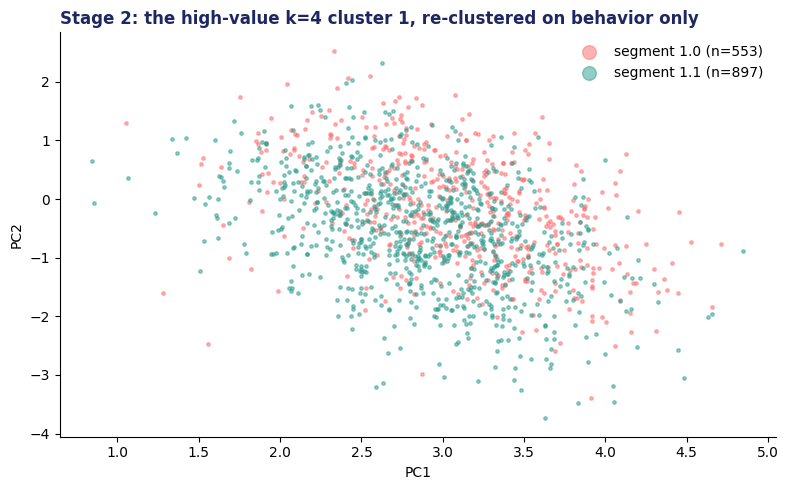


The two-stage result is what we carry forward (F['segment2']): a value tier first, then behavior inside it — the structure a brand team can explain in one sentence.


In [15]:
# Two-stage segmentation. Practitioners rarely cluster once, because k is never known: a value/behavior tier first, then behavior within the tier.
# Suppose the team had stopped at the elbow (k = 4). Where does the brand's value sit, and is that cluster one behavior or two?
km4 = KMeans(n_clusters=4, n_init=20, random_state=RNG).fit(Xs); F["cluster4"] = km4.labels_
big = F.groupby("cluster4").brand_trx.sum().idxmax()                          # the k=4 cluster holding the most brand TRx
sub = F[F.cluster4 == big]
print(f"k = 4 — cluster {big} holds {len(sub):,} HCPs and {sub.brand_trx.sum() / F.brand_trx.sum():.0%} of brand TRx.")
if "truth" in F: print(pd.crosstab(F.truth, F.cluster4, rownames=["planted"], colnames=["k=4 cluster"]))
BEHAV = ["brand_share", "share_trend", "nbrx_share", "switch_in_rate", "call_response", "email_open_rate", "web_visits"]
Xb = sub[BEHAV].copy(); Xb["web_visits"] = np.log1p(Xb.web_visits); Xb = StandardScaler().fit_transform(Xb)
sub_sil = {k: round(silhouette_score(Xb, KMeans(n_clusters=k, n_init=10, random_state=RNG).fit_predict(Xb)), 3) for k in [2, 3, 4]}
k2 = max(sub_sil, key=sub_sil.get)
km2 = KMeans(n_clusters=k2, n_init=20, random_state=RNG).fit(Xb)
F["segment2"] = F.cluster4.astype(str); F.loc[sub.index, "segment2"] = [f"{big}.{l}" for l in km2.labels_]
print(f"\nStage 2 on cluster {big}, behavior features only: silhouette by k = {sub_sil} → k = {k2}")
print(F.loc[sub.index].groupby("segment2")[["market_trx", "brand_share", "share_trend", "nbrx_share", "switch_in_rate", "call_response", "web_visits"]].mean().round(3))
if "truth" in F:
    print(f"\nARI vs planted — k=4 single stage: {adjusted_rand_score(F.truth, F.cluster4):.3f} | two-stage: {adjusted_rand_score(F.truth, F.segment2):.3f} | k=5 single stage: {adjusted_rand_score(F.truth, F.cluster):.3f}")
    print(pd.crosstab(F.truth, F.segment2, rownames=["planted"], colnames=["two-stage segment"]))
fig, ax = plt.subplots(figsize=(8, 5))
P2s = pca.transform(Xs[F.index.get_indexer(sub.index)])
for i, l in enumerate(sorted(set(km2.labels_))):
    m = km2.labels_ == l; ax.scatter(P2s[m, 0], P2s[m, 1], s=6, alpha=0.5, color=[CORAL, TEAL, GOLD, VIOLET][i], label=f"segment {big}.{l} (n={m.sum():,})")
ax.legend(frameon=False, markerscale=4); ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title(f"Stage 2: the high-value k=4 cluster {big}, re-clustered on behavior only", loc="left", color=NAVY, fontweight="bold")
show("twostage")
print("\nThe two-stage result is what we carry forward (F['segment2']): a value tier first, then behavior inside it — the structure a brand team can explain in one sentence.")

## 9. Supervised segmentation — predict growth, then rank
The unsupervised segments describe *how HCPs behave*. A brand team often wants something narrower: *who will grow, who will churn*. That is a supervised problem: predict the change in GLUCOREN share over the next six months from the feature-window features, then cut the predictions into groups — the PMSA "Brand Champions / Loyalists / Churners" pattern.

The outcome window (Jan–Jun 2026) is used here for the first time, as the label. We hold out 30% of HCPs to measure the model honestly.

Hold-out R² for 6-month share change: 0.418  (share change is noisy at HCP level; ranking is what matters — see the decile table)
Top drivers:
cluster_4              0.346
web_visits             0.164
share_trend            0.105
glucoren_reject_rate   0.096
brand_share            0.082
market_trx             0.051
cluster_3              0.027
nbrx_share             0.025
dtype: float64

Predicted-growth deciles vs what actually happened (all HCPs; deciles 9–10 = Champions, 1–2 = Churners):
               hcps  predicted  actual  brand_trx
growth_decile                                    
1               600     -0.056  -0.061      53192
2               600     -0.027  -0.029      28319
3               600     -0.011  -0.012      26342
4               600     -0.003  -0.003      23563
5               600      0.003   0.003      24483
6               600      0.008   0.007      22607
7               600      0.013   0.016      25917
8               600      0.024   0.029      72259
9   

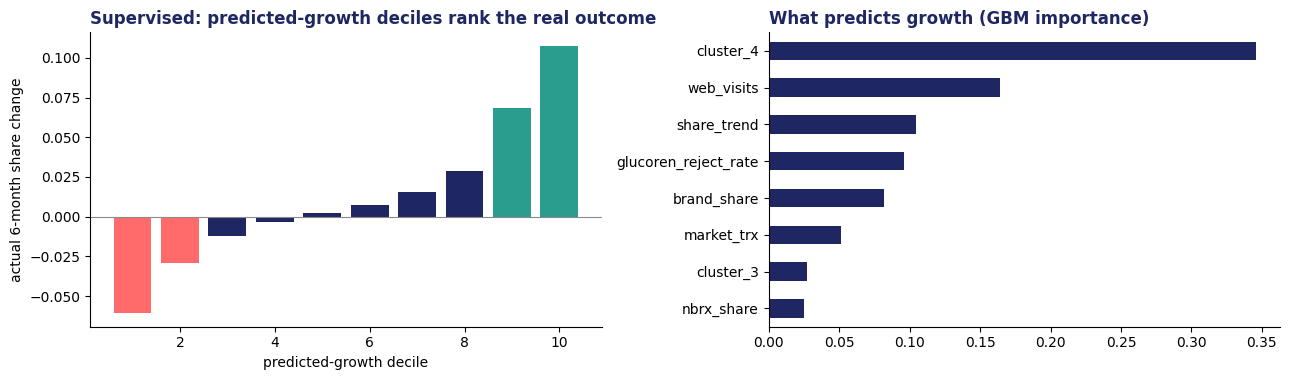


Unsupervised behavior × supervised outcome:
supervised_segment  Champions  Churn risk  Loyalists / stable
segment2                                                     
0                       0.020       0.190               0.790
1.0                     0.450       0.010               0.540
1.1                     1.000       0.000               0.000
2                       0.000       0.860               0.140
3                       0.000       0.030               0.970


In [16]:
out = monthly[monthly.month.isin(OUTCOME_MONTHS)].groupby("hcp_id")[["market_trx", "glucoren_trx"]].sum()
F["share_next"] = out.glucoren_trx / out.market_trx.clip(lower=1)
F["growth"] = F.share_next - F.brand_share                                    # change in share, next 6 months vs feature year
SUP = FEATURES + ["cluster"]
Xsup = pd.get_dummies(F[SUP], columns=["cluster"]).astype(float)
Xtr, Xte, ytr, yte = train_test_split(Xsup, F.growth, test_size=0.3, random_state=RNG)
gbr = GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, random_state=RNG).fit(Xtr, ytr)
r2 = gbr.score(Xte, yte); F["pred_growth"] = gbr.predict(Xsup)
imp = pd.Series(gbr.feature_importances_, index=Xsup.columns).sort_values(ascending=False)
print(f"Hold-out R² for 6-month share change: {r2:.3f}  (share change is noisy at HCP level; ranking is what matters — see the decile table)")
print("Top drivers:"); print(imp.head(8).round(3))
F["growth_decile"] = pd.qcut(F.pred_growth.rank(method="first"), 10, labels=range(1, 11)).astype(int)
gd = F.groupby("growth_decile").agg(hcps=("growth", "size"), predicted=("pred_growth", "mean"), actual=("growth", "mean"), brand_trx=("brand_trx", "sum")).round(4)
print("\nPredicted-growth deciles vs what actually happened (all HCPs; deciles 9–10 = Champions, 1–2 = Churners):"); print(gd)
def label(d): return "Champions" if d >= 9 else ("Churn risk" if d <= 2 else "Loyalists / stable")
F["supervised_segment"] = F.growth_decile.map(label)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.9))
axes[0].bar(gd.index, gd.actual, color=[CORAL if i <= 2 else (TEAL if i >= 9 else NAVY) for i in gd.index]); axes[0].axhline(0, color=GREY, lw=0.8)
axes[0].set_xlabel("predicted-growth decile"); axes[0].set_ylabel("actual 6-month share change"); axes[0].set_title("Supervised: predicted-growth deciles rank the real outcome", loc="left", color=NAVY, fontweight="bold")
imp.head(8)[::-1].plot.barh(ax=axes[1], color=NAVY); axes[1].set_title("What predicts growth (GBM importance)", loc="left", color=NAVY, fontweight="bold")
show("supervised")
print("\nUnsupervised behavior × supervised outcome:"); print(pd.crosstab(F.segment2, F.supervised_segment, normalize="index").round(2))

**Two different questions.** The cross-tab is the lesson: the behavioral segments tell you *what play to run*; the growth score tells you *whom to prioritize within it*. A "Churn risk" HCP inside an entrenched-competitor segment and one inside a high-share segment need different conversations. Next week's NBA layer uses both — the segment as the context, the score as the priority. Note what the importance chart surfaced: a patient-mix/access feature (the pharmacy-reject rate) predicts decline. In a real brand this is the moment the segmentation team walks over to market access.

## 10. From segments to personas and activation
A **persona** is the segment written as a person: a name, a one-line behavior, what they need, what they respond to. It is the bridge from the analytics team to the agency that writes the messages and to the field that has to believe the list. The rules: the name describes a *behavior* (never "Segment 3"); the size and the value are on the card; every persona gets a *different* play — channel, frequency, message; and the card says what would move an HCP *out* of the persona (that is next week's trigger).

Tonight we use the two-stage segments. Name them yourself first (exercise Part B), then compare with the reference names in the answer key.

          hcps  pct_brand_trx  share  trend  calls  call_resp  email_open    web  reject  medicare  churn_risk  calls_per_hcp_year_now
segment2                                                                                                                              
0         2424          0.081  0.106  0.003  4.876      0.005       0.199  7.255   0.089     0.388       0.187                   4.876
1.0        553          0.447  0.376  0.027 26.606      0.158       0.417 35.709   0.064     0.292       0.013                  26.606
1.1        897          0.163  0.163  0.078 16.897      0.081       0.378 50.530   0.063     0.276       0.000                  16.897
2          814          0.159  0.124 -0.006 21.743      0.029       0.300 21.498   0.308     0.603       0.859                  21.743
3         1312          0.150  0.063  0.006 19.275      0.014       0.142  6.062   0.072     0.347       0.030                  19.275

Channel affinity index (1.0 = universe average):
     

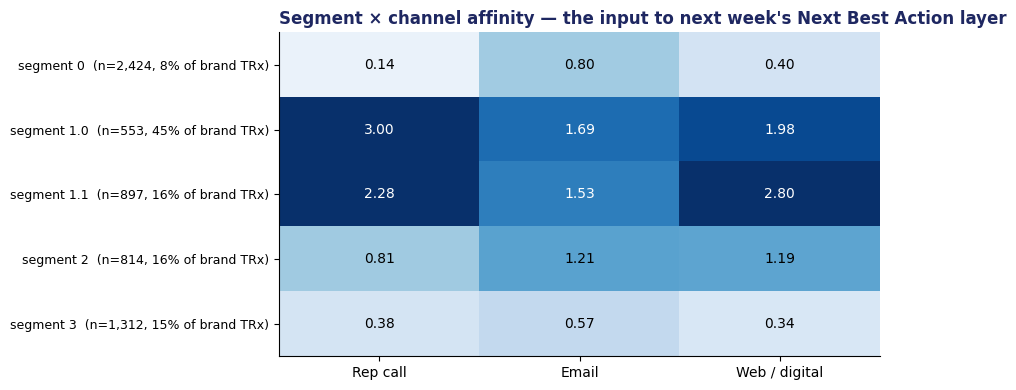

In [17]:
act = F.groupby("segment2").agg(hcps=("brand_trx", "size"), pct_brand_trx=("brand_trx", lambda s: s.sum() / F.brand_trx.sum()), share=("brand_share", "mean"), trend=("share_trend", "mean"),
                                  calls=("rep_calls", "mean"), call_resp=("call_response", "mean"), email_open=("email_open_rate", "mean"), web=("web_visits", "mean"),
                                  reject=("glucoren_reject_rate", "mean"), medicare=("pct_medicare", "mean"), churn_risk=("supervised_segment", lambda s: (s == "Churn risk").mean()))
act["calls_per_hcp_year_now"] = act.calls
# a simple affinity index per channel: the segment's response measure relative to the universe mean (1.0 = average)
aff = pd.DataFrame({"Rep call": act.call_resp / F.call_response.mean(), "Email": act.email_open / F.email_open_rate.mean(), "Web / digital": act.web / F.web_visits.mean()}, index=act.index).clip(0, 3)
print(act.round(3)); print("\nChannel affinity index (1.0 = universe average):"); print(aff.round(2))
fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(aff.values, cmap="Blues", vmin=0, vmax=2.2, aspect="auto")
ax.set_xticks(range(3)); ax.set_xticklabels(aff.columns); ax.set_yticks(range(len(aff))); ax.set_yticklabels([f"segment {i}  (n={act.hcps[i]:,}, {act.pct_brand_trx[i]:.0%} of brand TRx)" for i in aff.index], fontsize=9)
for i in range(len(aff)):
    for j in range(3): ax.text(j, i, f"{aff.iloc[i, j]:.2f}", ha="center", va="center", color="white" if aff.iloc[i, j] > 1.3 else "black", fontsize=10)
ax.set_title("Segment × channel affinity — the input to next week's Next Best Action layer", loc="left", color=NAVY, fontweight="bold")
show("activation")

## 11. Patient segmentation — the same machinery on journey features
The patient file is what a Week 2 pipeline produces: one row per GLUCOREN patient with journey features from claims (time from diagnosis to first fill, prior lines, PDC, refill gaps, switches, copay, comorbidity, ER visits) and from the brand's own programs (patient-support enrollment, portal logins). Segmenting patients answers a different set of questions — *who is at risk of stopping, who needs affordability help, who is a complex late-line patient the HCP needs support with* — and it carries governance obligations the HCP work does not (see the reading pack, Part D).

Silhouette by k: {2: 0.189, 3: 0.184, 4: 0.162, 5: 0.141, 6: 0.141, 7: 0.135}


         patients    age  months_on  prior_lines   pdc  gaps  switches  copay   psp  portal  comorb    er  discontinued  pct_medicare
cluster                                                                                                                              
0            6661 61.410     21.600        1.240 0.870 0.320     0.100 20.950 0.280   2.040   1.660 0.180         0.050         0.520
1            3094 63.310      7.050        3.280 0.660 1.360     1.490 36.960 0.360   3.250   3.430 0.790         0.270         0.570
2            5568 54.020      5.880        0.700 0.830 0.410     0.160 26.110 0.550   5.970   1.180 0.140         0.080         0.300
3            4677 66.130      9.030        1.070 0.510 2.670     0.350 68.930 0.120   1.200   2.010 0.330         0.420         0.690


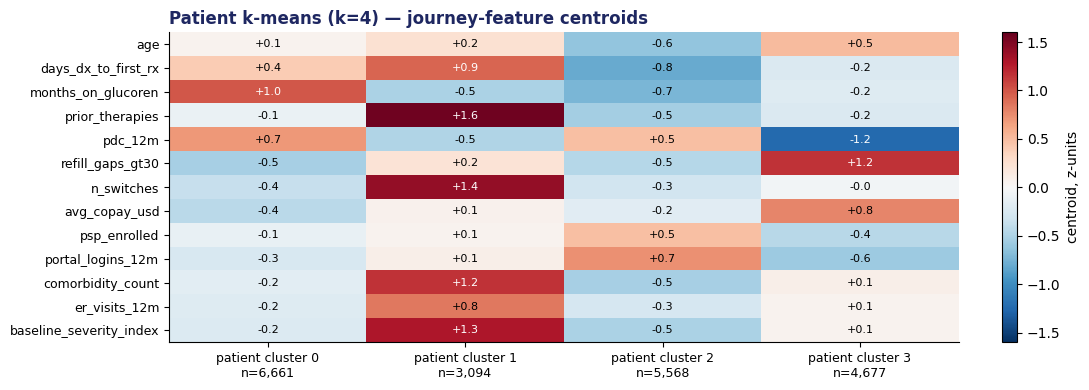


ARI vs planted patient behaviors: 0.842
cluster                       0     1     2     3
planted                                          
Complex Late-Line            65  3014    24   152
Cost-Sensitive Strugglers   162    71   106  4483
Engaged New Starters        166     0  5032    32
Stable Long-Term           6268     9   406    10


In [18]:
PF = ["age", "days_dx_to_first_rx", "months_on_glucoren", "prior_therapies", "pdc_12m", "refill_gaps_gt30", "n_switches", "avg_copay_usd",
      "psp_enrolled", "portal_logins_12m", "comorbidity_count", "er_visits_12m", "baseline_severity_index"]
Xp = patients[PF].copy()
for c in ["days_dx_to_first_rx", "months_on_glucoren", "avg_copay_usd", "portal_logins_12m"]: Xp[c] = np.log1p(Xp[c])
Xps = StandardScaler().fit_transform(Xp)
rp = np.random.default_rng(RNG).choice(len(Xps), 4000, replace=False)
psil = {k: silhouette_score(Xps[rp], KMeans(n_clusters=k, n_init=5, random_state=RNG).fit(Xps).labels_[rp]) for k in range(2, 8)}
print("Silhouette by k:", {k: round(v, 3) for k, v in psil.items()})
KP = 4
kmp = KMeans(n_clusters=KP, n_init=20, random_state=RNG).fit(Xps); patients["cluster"] = kmp.labels_
pprof = patients.groupby("cluster").agg(patients=("age", "size"), age=("age", "mean"), months_on=("months_on_glucoren", "mean"), prior_lines=("prior_therapies", "mean"),
                                        pdc=("pdc_12m", "mean"), gaps=("refill_gaps_gt30", "mean"), switches=("n_switches", "mean"), copay=("avg_copay_usd", "mean"),
                                        psp=("psp_enrolled", "mean"), portal=("portal_logins_12m", "mean"), comorb=("comorbidity_count", "mean"), er=("er_visits_12m", "mean"),
                                        discontinued=("discontinued", "mean"))
pprof["pct_medicare"] = patients.groupby("cluster").payer_type.apply(lambda s: (s == "Medicare Part D").mean())
print(pprof.round(2))
zc = pd.DataFrame(kmp.cluster_centers_, columns=PF)
fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(zc.T, cmap="RdBu_r", vmin=-1.6, vmax=1.6, aspect="auto"); ax.set_yticks(range(len(PF))); ax.set_yticklabels(PF, fontsize=9)
ax.set_xticks(range(KP)); ax.set_xticklabels([f"patient cluster {c}\nn={(patients.cluster == c).sum():,}" for c in range(KP)], fontsize=9)
for i in range(len(PF)):
    for j in range(KP): ax.text(j, i, f"{zc.iloc[j, i]:+.1f}", ha="center", va="center", fontsize=8, color="white" if abs(zc.iloc[j, i]) > 0.9 else "black")
plt.colorbar(im, fraction=0.03, label="centroid, z-units"); ax.set_title(f"Patient k-means (k={KP}) — journey-feature centroids", loc="left", color=NAVY, fontweight="bold")
show("patient_profile")
pt = INSTR / "_INSTRUCTOR_patient_segment_truth.csv"
if pt.exists():
    ptruth = pd.read_csv(pt).set_index("patient_id").true_segment; patients["truth"] = patients.patient_id.map(ptruth)
    print(f"\nARI vs planted patient behaviors: {adjusted_rand_score(patients.truth, patients.cluster):.3f}")
    print(pd.crosstab(patients.truth, patients.cluster, rownames=["planted"], colnames=["cluster"]))
else:
    print("Instructor patient truth file not found — grading skipped.")

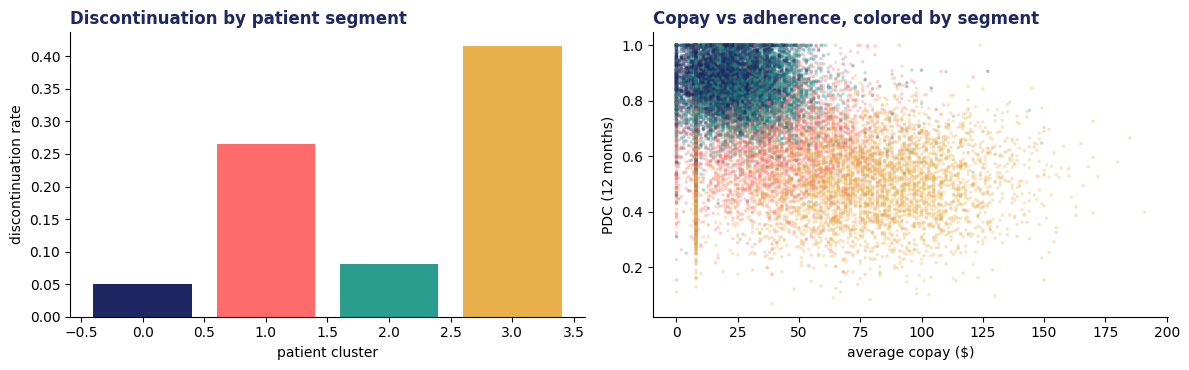

         patients  discontinued   pdc  copay   psp
cluster                                           
0            6661         0.050 0.872 20.950 0.275
1            3094         0.265 0.656 36.960 0.356
2            5568         0.081 0.834 26.110 0.554
3            4677         0.416 0.514 68.934 0.117

Governance reminder: a patient segment is an output about a person. It is used for the program it was built for (adherence support, affordability routing), labeled with its purpose and refresh date, and never re-purposed for HCP targeting or shared outside the approved use — see the IQVIA purpose-limitation excerpt in the reading pack.


In [19]:
# What each patient segment is for — discontinuation risk and the program that fits
risk = patients.groupby("cluster").agg(patients=("age", "size"), discontinued=("discontinued", "mean"), pdc=("pdc_12m", "mean"), copay=("avg_copay_usd", "mean"), psp=("psp_enrolled", "mean"))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(risk.index, risk.discontinued, color=[CLUSTER_COLORS[c] for c in risk.index]); axes[0].set_xlabel("patient cluster"); axes[0].set_ylabel("discontinuation rate")
axes[0].set_title("Discontinuation by patient segment", loc="left", color=NAVY, fontweight="bold")
axes[1].scatter(patients.avg_copay_usd, patients.pdc_12m, s=3, alpha=0.2, c=[CLUSTER_COLORS[c] for c in patients.cluster]); axes[1].set_xlabel("average copay ($)"); axes[1].set_ylabel("PDC (12 months)")
axes[1].set_title("Copay vs adherence, colored by segment", loc="left", color=NAVY, fontweight="bold")
show("patient_risk")
print(risk.round(3))
print("\nGovernance reminder: a patient segment is an output about a person. It is used for the program it was built for (adherence support, affordability routing), labeled with its purpose and refresh date, and never re-purposed for HCP targeting or shared outside the approved use — see the IQVIA purpose-limitation excerpt in the reading pack.")

## 12. What to take into Week 5
- **Deciles rank; segments explain.** Keep both — the decile is the volume axis, the behavioral segment is the play.
- **Features are the model.** Four families from claims/Rx and channel data; log the counts, prefer rates, watch the double-counting.
- **Choose k with three lenses** — statistics, stability, and *can marketing run k plays?* — and expect to cluster twice.
- **Stability before separation before interpretability**, and all three before a persona.
- **Supervised ≠ unsupervised.** Behavior is the context; the growth score is the priority. Next week's NBA engine consumes both.
- **Patients are different.** Same machinery, different questions, real governance.

Bring to Week 5: your named segments (exercise Part B) and one HCP from each — the NBA engine will decide what to do with them.